<a href="https://colab.research.google.com/github/Serip1/PPEC---Estatistica/blob/main/Trabalho_final_Estatistica_Jo%C3%A3o_Paulo_Pires.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Na presente pesquisa foi verificado a influencia da adição de fibras vegetais (fibra de sisal) para a retração e as propriedades fisico-mecanicas de matrizes geopolímericas. Nesse etapa, iremos verificar as alterações da adição de fibras vegetais para a resistencia a compressão do composito nas idades de 1 dia, 14 dias e 28 dias. Iremos importar os resultados encontrados por um arquivo CSV localizado em um repositorio em meu Git Hub

In [ ]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
tabela = pd.read_csv('https://raw.githubusercontent.com/Serip1/PPEC---Estatistica/refs/heads/main/resistencia%20a%20compress%C3%A3o%20-%20Jo%C3%A3o%20-%20CSV.csv')
print(tabela)

   amostra  teor  idade  resistencia
0      Ref  0.00      1         18.5
1      Ref  0.00      1         17.0
2      Ref  0.00      1         20.2
3      Ref  0.00     14         26.8
4      Ref  0.00     14         25.8
5      Ref  0.00     14         23.3
6      Ref  0.00     28         31.6
7      Ref  0.00     28         33.5
8      Ref  0.00     28         32.6
9       1%  0.01      1         17.9
10      1%  0.01      1         17.9
11      1%  0.01      1         20.8
12      1%  0.01     14         34.7
13      1%  0.01     14         28.6
14      1%  0.01     14         32.2
15      1%  0.01     28         31.6
16      1%  0.01     28         32.0
17      1%  0.01     28         31.5
18      2%  0.02      1         17.2
19      2%  0.02      1         18.9
20      2%  0.02      1         20.4
21      2%  0.02     14         25.5
22      2%  0.02     14         30.1
23      2%  0.02     14         31.5
24      2%  0.02     28         29.1
25      2%  0.02     28         24.8
2

Vamos fazer a matriz de correlação entre os valores de teores de fibras, idade do composito (tempo de cura) e resistencia a compressão das amostras. para isso, vamos retirar a primeira coluna, que possui dados em string, para poder utilizar corretamente a tabela

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sn

tabela3 = tabela.drop('amostra', axis=1)

print(tabela3)

    teor  idade  resistencia
0   0.00      1         18.5
1   0.00      1         17.0
2   0.00      1         20.2
3   0.00     14         26.8
4   0.00     14         25.8
5   0.00     14         23.3
6   0.00     28         31.6
7   0.00     28         33.5
8   0.00     28         32.6
9   0.01      1         17.9
10  0.01      1         17.9
11  0.01      1         20.8
12  0.01     14         34.7
13  0.01     14         28.6
14  0.01     14         32.2
15  0.01     28         31.6
16  0.01     28         32.0
17  0.01     28         31.5
18  0.02      1         17.2
19  0.02      1         18.9
20  0.02      1         20.4
21  0.02     14         25.5
22  0.02     14         30.1
23  0.02     14         31.5
24  0.02     28         29.1
25  0.02     28         24.8
26  0.02     28         29.4
27  0.03      1         18.8
28  0.03      1         18.2
29  0.03      1         20.2
30  0.03     14         33.9
31  0.03     14         32.3
32  0.03     14         34.5
33  0.03     2

agora com a nova tabela, iremos desenvolver nossa matriz de correlações

<Axes: >

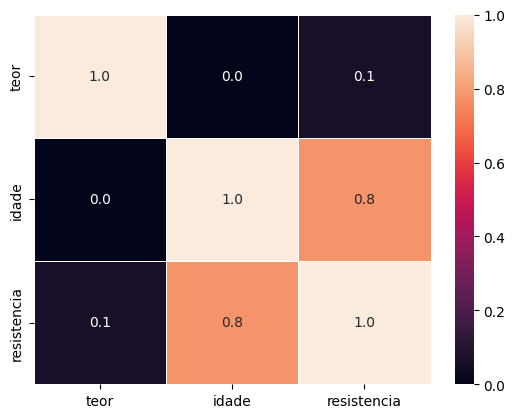

In [ ]:
correlation = tabela3.corr()
plot = sn.heatmap(correlation, annot = True, fmt=".1f", linewidths=.6)
plot

É possivel perceber atráves da tabela de correlações que a idade do composito geopolímerico apresenta boa correlação com a sua resistencia, o que é esperado para uma matriz cimenticia visto que suas reações de densificação ocorrem ao longo do tempo. Outra informação que podemos retirar é que o teor de fibras possui baixa correlação com a resistencia a compressão do material, o que também é esperado visto que as fibras são utilizadas para melhorar apenas a resistencia a tração do composito

Agora iremos realizar a Analise de variancia (ANOVA) para verificar se os valores encontrados para as resistencias com diferentes adições de fibras são significativamente diferentes. Para isso vamos restringir a tabela para apenas apresentar os resultados de 1 dia de cura

In [ ]:
tabela_1d = tabela[tabela['idade'] == 1]
print(tabela_1d)

   amostra  teor  idade  resistencia
0      Ref  0.00      1         18.5
1      Ref  0.00      1         17.0
2      Ref  0.00      1         20.2
9       1%  0.01      1         17.9
10      1%  0.01      1         17.9
11      1%  0.01      1         20.8
18      2%  0.02      1         17.2
19      2%  0.02      1         18.9
20      2%  0.02      1         20.4
27      3%  0.03      1         18.8
28      3%  0.03      1         18.2
29      3%  0.03      1         20.2


Agora, com a tabela reduzida, vamos realizar a analise de variancia para a tabela reduzida e verificar se há variação significativa para a resistencia de compositos com diferentes teores de fibras para a idade de 1 dia

In [ ]:
model = ols('resistencia ~ amostra', data=tabela_1d).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print(anova_table)

             sum_sq   df         F    PR(>F)
amostra    0.380000  3.0  0.056401  0.981157
Residual  17.966667  8.0       NaN       NaN


Agora vamos avaliar os resultados encontrados pela analise de variancia através de um simples teste logico se os resultados encontrados possuem diferenças significativas ou não.

In [ ]:
if anova_table['PR(>F)'].iloc[0] < 0.05:
  print("Há diferenças significativas entre os grupos (p < 0.05)")
else:
  print("Não há diferenças significativas entre os grupos (p > 0.05)")

Não há diferenças significativas entre os grupos (p > 0.05)


O que implica que não há evidencia estatística suficente para considerar que há alteração na resistencia a compressão com a adição de 1%, 2% ou 3% de fibras de sisal. Por ultimo vamos visualizar os dados da tabela no formato boxplot para mostrar graficamente os resultados

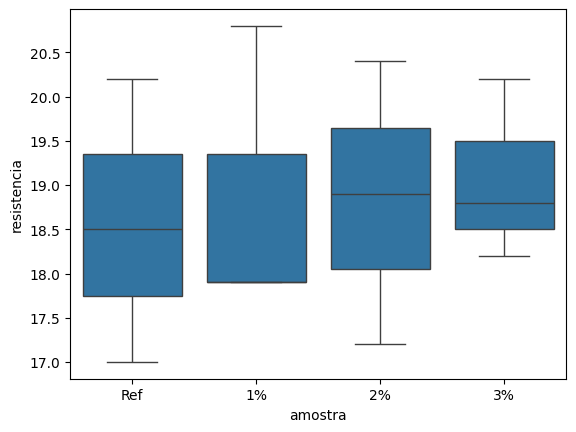

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=tabela_1d, x='amostra', y='resistencia')
plt.show()

Agora vamos realizar uma regressão linear para determinar a melhor equação que descreve a retração linear da matriz geopolimerica ao longo dos dias e sem a adição de fibras. A curva será do tipo y=a+b*x^(1/c) e será efetuada a partir dos valores encontrados  experimentalmente de retração linear ao longo dos dias. Vamos realizar a importação desses dados a partir de dados CSV localizados no mesmo repositório no Git Hub

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
tabela2 = pd.read_csv('https://raw.githubusercontent.com/Serip1/PPEC---Estatistica/refs/heads/main/retra%C3%A7%C3%A3o%20linear%20-%20Jo%C3%A3o%20-%20CSV.csv')
print(tabela2)

    dias     Cp1     Cp2
0      0   0.000   0.000
1      1   7.760   7.888
2      2   9.048   9.120
3      3   9.108   9.260
4      5   9.672   9.772
5      6   9.804   9.904
6      7   9.932  10.032
7      8   9.972  10.060
8      9  10.048  10.132
9     10  10.332  10.424
10    13  10.180  10.264
11    14  10.240  10.328
12    15  10.248  10.340
13    16  10.236  10.324
14    20  10.384  10.472
15    22  10.380  10.468
16    23  10.360  10.452
17    26  10.444  10.532
18    30  10.476  10.548
19    32  10.536  10.612
20    40  10.516  10.596
21    46  10.552  10.616
22    54  10.716  10.812
23    56  10.520  10.612


Vamos então definir a função que iremos usar para ajustar os dados. Como visto anteriormente, a curva será do tipo y=a+b*x^(1/c)

In [ ]:
def retracao_funcao(x, a, b, c):
    return a + b * x**(1/c)

Agora vamos ajustar os dados encontrados. Como a tabela possui duas colunas referentes a dois corpos de prova, a solução encontrada foi realizar a concatenação dos resultados de x e de y para ajustar os dados para a utilização da função curve_fit

In [ ]:
x = tabela2['dias'].values
x_concat = pd.concat([tabela2['dias'], tabela2['dias']])
y_concat = pd.concat([tabela2['Cp1'], tabela2['Cp2']])

popt, pcov = curve_fit(retracao_funcao, x_concat, y_concat)


Agora vamos visualizar os resultados da curva ajustada juntamente com os resultados encontrados

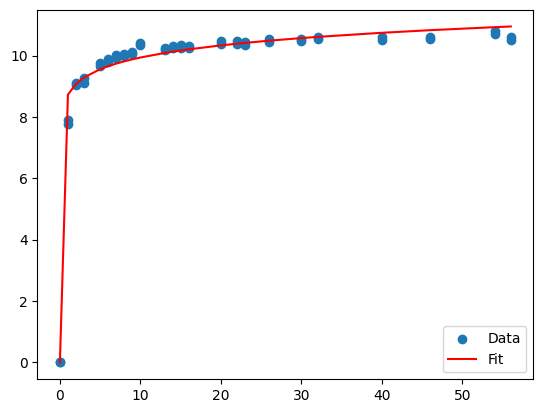

In [ ]:
plt.scatter(x_concat, y_concat, label='Data')
plt.plot(x, retracao_funcao(x, *popt), 'r-', label='Fit')
plt.legend()
plt.show()

Por ultimo vamos visualizar os parametros a,b e c da curva e que foram ajustados pelos pontos obtidos pelo ensaio

In [ ]:
print(f'Parâmetros ajustados: a = {popt[0]:.2f}, b = {popt[1]:.2f} e c = {popt[2]:.2f}')

Parâmetros ajustados: a = -0.01, b = 8.74 e c = 17.77
